# Softmax (Multinomial) Logistic Regression
Updated from binary logistic regression to support multi-class classification, L1/L2 solver compatibility, multi-class coefficient aggregation, and calibrated probability predictions (`predict_proba`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_val_score

In [2]:
data_raw = pd.read_csv('Data/Training_Data.csv', index_col=0).dropna().reset_index(drop=True)

Thres = 0.5
target_class = '%_mem_succs'

# Explicitly drop target and non-feature columns regardless of column order
drop_cols = [c for c in [target_class, 'valid_time'] if c in data_raw.columns]
Xtrain = data_raw.drop(columns=drop_cols)
ytrain = data_raw[target_class]

ytrain = ytrain.between(Thres,1)

features = Xtrain.columns

In [3]:
# Create a scaler object
scaler = StandardScaler()

# Use the fit_transform method to perform the normalization of columns
Xtilde = scaler.fit_transform(Xtrain)

# Put the transformed data into a DataFrame similar to Xtrain
Xtrain_norm = pd.DataFrame(Xtilde, columns=Xtrain.columns, index=Xtrain.index)

In [4]:
# 1. Correlation of each of the input columns with the target (requires numeric ytrain)
corr = Xtrain.corrwith(ytrain)

print(abs(corr).sort_values(ascending=False).head(10))

# 2. Take absolute value, sort in descending order, keep the first index.
best_single_feature = abs(corr).sort_values(ascending=False).index[0]

z300_max        0.202928
z300_min        0.194510
temp300_max     0.194251
temp300_min     0.192989
temp400_mean    0.191404
temp300_mean    0.189140
temp400_max     0.187540
z400_max        0.178367
temp400_min     0.172357
z400_min        0.151806
dtype: float64


In [5]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(solver='saga', max_iter=2000,l1_ratio=0))
])
pipeline.fit(Xtrain[[best_single_feature]], ytrain)
pipeline_perf = np.average(
    cross_val_score(pipeline, Xtrain[[best_single_feature]], ytrain, cv=5, scoring='neg_log_loss')
)

In [11]:
# Create a logarithmically spaced array of 20 values ranging from 0.01 to 100
Cs = np.logspace(-2, 2, 20)

# Initialize perfs to an empty array of 20 values
perfs = np.empty(20)

# Initialize models to an empty list
models = []

for c, C in enumerate(Cs):
    # Use 'saga' solver with L1 regularization (or 'lbfgs' with L2) for multinomial softmax
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(C=C, l1_ratio= 0, solver='lbfgs', max_iter=2000))
    ])

    # Store the model in the models list
    models.append(model)

    # Fit the model using the training data
    model.fit(Xtrain, ytrain)

    # Estimate performance using 5-fold CV with negative log-loss for probability calibration
    perfs[c] = np.average(
        cross_val_score(model, Xtrain, ytrain, cv=5, scoring='neg_log_loss')
    )

Text(0, 0.5, '||coef||_2 across classes')

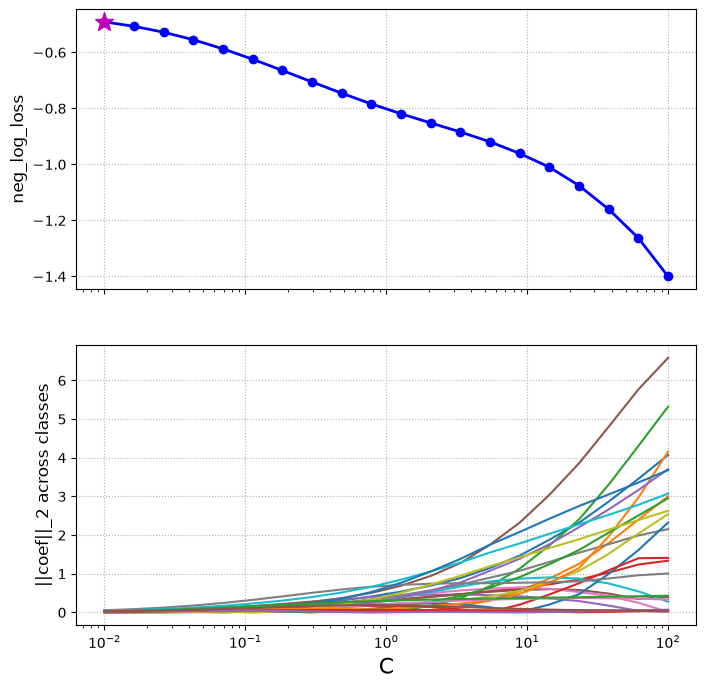

In [12]:
# 1. Set `cstar` to the index of the best performing regularization value
cstar = np.argmax(perfs)

# 2. Set `perf_star` to the corresponding performance score
perf_star = perfs[cstar]

# Aggregate multi-class coefficients (shape: n_classes x n_features) via L2 norm across classes
theta = np.vstack([
    np.linalg.norm(model.named_steps['logreg'].coef_, axis=0)
    for model in models
])

# 3. Plot the score as a function of `C`.
fig, ax = plt.subplots(figsize=(8, 8), nrows=2, sharex=True)
ax[0].semilogx(Cs, perfs, 'o-', color='b', linewidth=2)
ax[0].semilogx(Cs[cstar], perf_star, '*', color='m', markersize=14)
ax[0].grid(linestyle=':')
ax[0].set_ylabel('neg_log_loss', fontsize=12)

# 4. In a single plot, plot the aggregated feature coefficient norms as a function of `C`.
ax[1].semilogx(Cs, theta)
ax[1].grid(linestyle=':')
ax[1].set_xlabel('C', fontsize=16)
ax[1].set_ylabel('||coef||_2 across classes', fontsize=12)

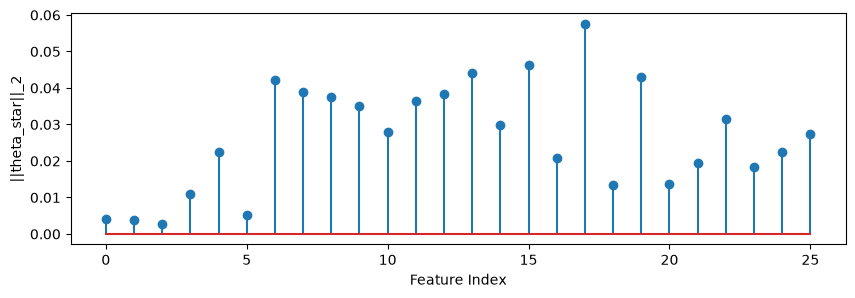

In [8]:
theta_star = theta[cstar, :]

plt.figure(figsize=(10, 3))
plt.stem(theta_star)
plt.ylabel('||theta_star||_2')
plt.xlabel('Feature Index');

In [9]:
features = Xtrain.columns

# 1. Set `best_features` to the set of feature names with non-zero coefficient norms
best_features = features[theta_star > 0]

# 2. Set `max_theta_feature` to the feature name with the largest coefficient norm
max_theta_feature = features[np.argmax(theta_star)]

# 3. Save the selected model to the variable `lasso_model`.
lasso_model = models[cstar]

In [14]:
# Output softmax class probabilities (each row sums to 1.0)
probs = lasso_model.predict_proba(Xtrain)
classes = lasso_model.named_steps['logreg'].classes_

probs_df = pd.DataFrame(probs, columns=[f'prob_class_{c}' for c in classes], index=Xtrain.index)
probs_df.head(5)

,prob_class_False,prob_class_True
0,0.112370,0.887630
1,0.121995,0.878005
2,0.120618,0.879382
3,0.111075,0.888925
4,0.116375,0.883625
